<a href="https://colab.research.google.com/github/Salax2/AI/blob/main/2026_brain_cancer_classification_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Brain tumour image classification with CNNs


**Assessment:** PASS/FAIL; complete the assessed tasks and explain your results to a GTA.  
**Choice:** Part 1 (this notebook) **or** Part 2 (NLP, separate activity in the accompanying brief).

### Learning outcomes
1. Load and inspect a three-class image dataset, including class imbalance.
2. Design, compile and train a CNN using TensorFlow/Keras.
3. Compare **three controlled experiments** using validation results.
4. Select a model without using the test set during development.
5. Interpret accuracy, precision, recall, F1-score and a confusion matrix.

**Important:** This is an educational exercise, not a validated medical diagnostic system. The dataset comes from the `BrainTumorDataset.zip`; it is **not bundled** in this notebook.

**Working rule:** Run cells from the top. Change only the parameters explicitly requested. The test set is reserved for the *final* model after selection.

### Workflow and evidence

| Stage | Dataset | Purpose |
|---|---|---|
| 1. Fit the CNN | **Training** | Learn model weights; class weights may be applied here |
| 2. Compare experiments | **Validation** | Compare A, B and C; select the best model by **validation macro-F1** (tie-break: lower validation loss) |
| 3. Evaluate chosen model | **Testing** | One final evaluation; do **not** use these results to revise the model |

**Report these experiments:** A = baseline (no dropout, no class weights); B = dropout only; C = dropout plus class weights. D = An experiment proposed by you. Keep dataset split, architecture other than dropout, random seed, maximum epochs and image resolution fixed.

**Assessment evidence:** class-count table, example images, model summary, three-row experiment table, raw learning curves, final classification report/confusion matrix, and concise explanations.

# Import necessary libraries

In [ ]:
%matplotlib inline
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os
import PIL
import PIL.Image
import tensorflow_datasets as tfds
import pathlib
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight

# Set the default figure size for matplotlib
plt.rcParams['figure.figsize'] = (7,7) # Make the figures a bit bigger

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow version:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Load data and preprocess it

## Upload the data to drive:
Download the dataset from Brigthspace, and upload it to the content folder in Google Colab.


###Option 1: To avoid having to upload the dataset every time, you can upload the dataset to your google drive, and then connect this virtual machine to your drive, and make a copy of your data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Replace the path /content/drive/MyDrive/Work/2025-CS3002/BrainTumorDataset.zip with your actual path where you copied the dataset in your drive.

In [ ]:
!cp /content/drive/MyDrive/Work/2026-CS3613/BrainTumorDataset.zip /content/

###Option 2: Upload the zip archive in the Files section of your virtual machine, under /content/

###After the data is loaded, let's start processing it.

In [ ]:
# After you have copied the data locally, point the dataset_url to the local path
dataset_url = '/content/BrainTumorDataset.zip'

In [ ]:
import zipfile
import os

# Path to your local zip file
zip_path = dataset_url

# Path where you want to extract
out_path = "/content/"

# Extract
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(out_path)

print("Extraction complete. Files are in:", out_path)


Extraction complete. Files are in: /content/


In [ ]:
# Create a 'pathlib.Path' object for the downloaded archive
# Pathlib module offers classes representing filesystem paths with semantics
# appropriate for different operating systems.
# data_dir = pathlib.Path(archive).with_suffix('')

extract_dir = pathlib.Path(zip_path).with_suffix('')
# Now use Pathlib for further work
data_dir = pathlib.Path(extract_dir)

print("Data directory is:", data_dir)

Data directory is: /content/BrainTumorDataset


In [ ]:
# Count the number of images in a specific directory
image_count = len(list(data_dir.glob('./Training/glioma/*.jpg')))
print(image_count)

500


**T1A.** Count the number of images for each class in each split. State which split(s) are balanced. Explain why training imbalance might affect overall accuracy and per-class recall.

In [ ]:
# BEGIN YOUR CODE HERE

# Brain tumour dataset is split into train, validation and test folders. Inside those folders you will
# find additional folders: glioma, pituitary, notumor. You can explore the folders using
# 'Files' tab from the right hand side.
# Tip: use the len() function

# 1a. How many images do we have in training for positive glioma? How many for pituitary? How many for no tumour?
for tumor in["glioma", "notumor", "pituitary"]:
    folder = data_dir / "Training" / tumor
    count = (len(list(folder.glob("*.jpg"))))
    print (tumor,  count)

# 1b. How about in the validation set?
for tumor in["glioma", "notumor", "pituitary"]:
    folder = data_dir / "Validation" / tumor
    count = (len(list(folder.glob("*.jpg"))))
    print (tumor,  count)

# 1c. How about in the testing set?
for tumor in["glioma", "notumor", "pituitary"]:
    folder = data_dir / "Testing" / tumor
    count = (len(list(folder.glob("*.jpg"))))
    print (tumor,  count)


# END YOUR CODE HERE

glioma 500
notumor 1550
pituitary 500
glioma 150
notumor 150
pituitary 150
glioma 300
notumor 300
pituitary 300


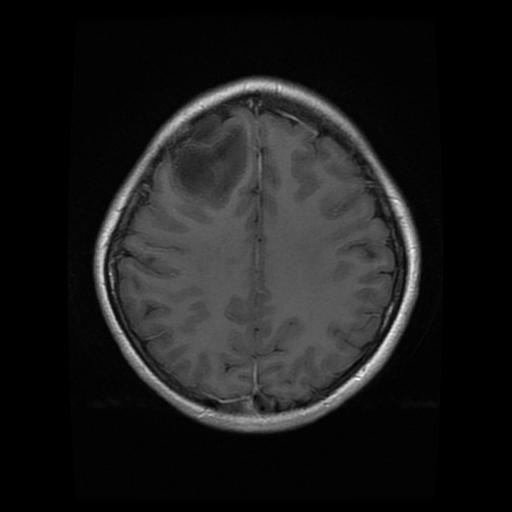

In [ ]:
# Create a list of file paths for glioma images
positive_images = list(data_dir.glob('Training/glioma/*'))
# Open and display the first glioma image in the list
PIL.Image.open(str(positive_images[0]))

**T1B.** Display **one validation image per class**. In your answer, explain what resizing to a common image shape accomplishes and one potential limitation of image resizing.

glioma


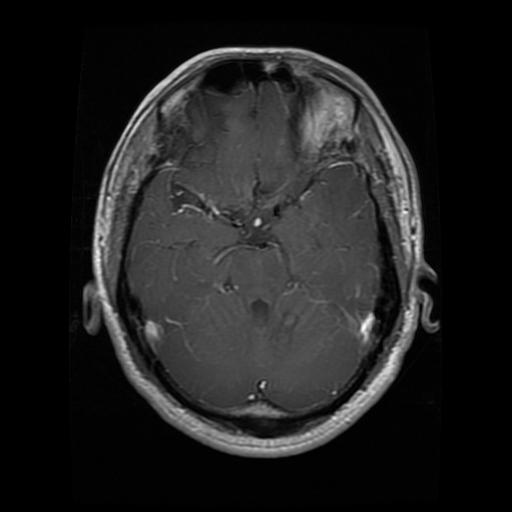

notumor


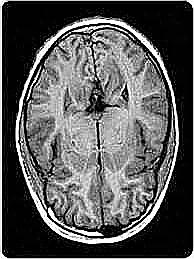

pituitary


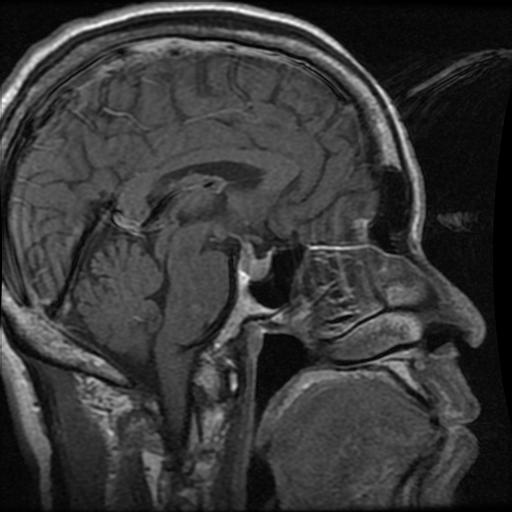

In [ ]:
# BEGIN YOUR CODE HERE
# 2. Display one glioma, one pituitary, and a normal image from the validation dataset
from PIL import Image
for tumor in ["glioma", "notumor", "pituitary"]:
  positive_images = list((data_dir / "Validation" / tumor).glob("*.jpeg"))[0]
  print(tumor)
  display(Image.open(positive_imagesimage))
# END YOUR CODE HERE

**T1C.** Explain why unequal training-class frequencies may affect the model’s predictions and evaluation metrics

The reason is because the training dataaset has more notumor images comapred to the glioma and pituitary images, thus the model will be more biased towards the notumor class and make more mistakes on the pituitary and the glioma which can affect the accuracy and cause it to be inaccurate.

# Task 2. Define a deep learning model that will learn the differences between glioma and no tumour images


In [ ]:
# Define batch size and image dimensions for training

# BEGIN YOUR CODE HERE
# The batch size is the number of samples processed before the model is updated.
# Choose an appropriate batch size. What are the images resolutions?

batch_size = 32
img_height = 128
img_width = 128

# What is the resolution of the images?
# Specify the size to resize images to after they are read from disk.
# Since the pipeline processes batches of images that must all have the same size, this must be provided.



# END YOUR CODE HERE

In [ ]:
import os
from PIL import Image

def find_min_max_resolutions(folder_path):
    min_res = None
    max_res = None
    min_file = None
    max_file = None

    for root, _, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif', '.tiff')):
                file_path = os.path.join(root, file)
                try:
                    with Image.open(file_path) as img:
                        width, height = img.size
                        resolution = width * height

                        # Update min
                        if min_res is None or resolution < min_res:
                            min_res = resolution
                            min_file = (file_path, (width, height))

                        # Update max
                        if max_res is None or resolution > max_res:
                            max_res = resolution
                            max_file = (file_path, (width, height))

                except Exception as e:
                    print(f"Could not process {file_path}: {e}")

    return min_file, max_file

# Example usage:

folder = "/content/BrainTumorDataset/Training/notumor/"
min_file, max_file = find_min_max_resolutions(folder)

print(f"Smallest image: {min_file[0]} with resolution {min_file[1]}")
print(f"Largest image: {max_file[0]} with resolution {max_file[1]}")


Smallest image: /content/BrainTumorDataset/Training/notumor/Tr-no_0923.jpg with resolution (150, 198)
Largest image: /content/BrainTumorDataset/Training/notumor/Tr-no_1005.jpg with resolution (1920, 1080)


In [ ]:
train_data_dir  = os.path.join(data_dir,'Training')
valid_data_dir = os.path.join(data_dir,'Validation')
test_data_dir = os.path.join(data_dir,'Testing')

In [ ]:
# Create a TensorFlow image dataset from a directory
# BEGIN YOUR CODE HERE
# Use the function tf.keras.utils.image_dataset_from_directory to load
# the training dataset: https://www.tensorflow.org/api_docs/python/tf/keras/utils/image_dataset_from_directory
# 1. First argument is your training directory folder (train_data_dir),
# 2. Do NOT use validation_split since we only want a training set,
# 3. You can set a seed such that when you repeat experiments you get similar results, e.g. seed=123,
# 4. For image size, use the img_height and img_width variables you defined previously,
# 5. For batch size, use the batch_size variable you defined earlier in the code.
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    validation_split=None,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    shuffle=False
 )


val_ds = tf.keras.utils.image_dataset_from_directory(
    valid_data_dir,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    class_names=train_ds.class_names,
    shuffle=False
)

# Example:




# END YOUR CODE HERE

Found 2550 files belonging to 3 classes.
Found 450 files belonging to 3 classes.


In [ ]:
# Create a layer to normalise pixel values to the [0, 1] range.
# By default, when you load an image, each pixel value will have a value between 0-255
# but, in neural networks, we need as input normalised values in [0,1] interval.
normalization_layer = tf.keras.layers.Rescaling(1./255)

In [ ]:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixel values are now in `[0,1]`.
print(np.min(first_image), np.max(first_image), first_image[0][0])

0.0 0.909804 tf.Tensor([0. 0. 0.], shape=(3,), dtype=float32)


In [ ]:
# BEGIN YOUR CODE HERE
# Define the number of classes in the classification problem
# How many classes do we have in this dataset?
num_classes = 3


# END YOUR CODE HERE

## Task 3 | Four controlled experiments

A: no dropout, no weighting.  B: dropout rate, no weighting.  C: dropout rate plus inverse-frequency class weights.  All other experimental settings remain fixed. D. Your own propose experiment. Each run **builds a new model** and resets the random seed. An `EarlyStopping` callback restores the weights with lowest validation loss.

Calculate training-only class weights using `N / (K × n_class)` and explain which class receives the largest weight and why.


In [ ]:
# Extract training labels
y_train = np.concatenate([y for x, y in train_ds], axis=0)

# Compute class weights
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(class_weights))
print("Class Weights:", class_weights)

# TIP: Search how you can use the class weights during training to improve your results

Class Weights: {0: np.float64(1.7), 1: np.float64(0.5483870967741935), 2: np.float64(1.7)}


Helper function for visualisation

In [ ]:
from scipy.ndimage import gaussian_filter1d  # for smoothing

# function to plot loss/accuracy with trend lines
def plot_loss_accuracy(history, smooth_sigma=2):
    # Extract loss and accuracy values
    loss_values = history.history['loss']
    acc_values = history.history['accuracy']

    # Validation (if available)
    val_loss = history.history.get('val_loss')
    val_acc = history.history.get('val_accuracy')

    epochs = np.arange(1, len(loss_values) + 1)

    # --- Plot Training & Validation Loss ---
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss_values, marker='o', linestyle='-', color='b', alpha=0.5, label='Training Loss')
    # plt.plot(epochs, gaussian_filter1d(loss_values, sigma=smooth_sigma), color='b', linewidth=2, label='Trend (Train)')

    if val_loss is not None:
        plt.plot(epochs, val_loss, marker='x', linestyle='--', color='r', alpha=0.5, label='Validation Loss')
        # plt.plot(epochs, gaussian_filter1d(val_loss, sigma=smooth_sigma), color='r', linewidth=2, label='Trend (Val)')

    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Loss Over Epochs')
    plt.grid(True)
    plt.legend()

    # --- Plot Training & Validation Accuracy ---
    plt.subplot(1, 2, 2)
    plt.plot(epochs, acc_values, marker='o', linestyle='-', color='g', alpha=0.5, label='Training Accuracy')
    # plt.plot(epochs, gaussian_filter1d(acc_values, sigma=smooth_sigma), color='g', linewidth=2, label='Trend (Train)')

    if val_acc is not None:
        plt.plot(epochs, val_acc, marker='x', linestyle='--', color='orange', alpha=0.5, label='Validation Accuracy')
        # plt.plot(epochs, gaussian_filter1d(val_acc, sigma=smooth_sigma), color='orange', linewidth=2, label='Trend (Val)')

    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.title('Accuracy Over Epochs')
    plt.grid(True)
    plt.legend()

    plt.tight_layout()
    plt.show()

**T3B.** Train A, B, C and D. Use the provided configuration and logging structure. For each experiment, report validation accuracy, macro-F1, loss, elapsed epochs and number of parameters. **Do not call `test_ds` here.**

In [ ]:
# BEGIN YOUR CODE HERE

model_A = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(img_height, img_width, 3)),
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(num_classes)
])

# compile the model
model_A.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_A.summary()


# END YOUR CODE HERE

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,686,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,692,003 (14.08 MB)

 Trainable params: 3,692,003 (14.08 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# TRAIN MODEL A
# BEGIN YOUR CODE HERE

# TRAIN MODEL A

history_A = model_A.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds
)




# END YOUR CODE HERE

Epoch 1/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 22s 165ms/step - accuracy: 0.7157 - loss: 3.4109 - val_accuracy: 0.3600 - val_loss: 1.0740
Epoch 2/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.5243 - loss: 3.2122 - val_accuracy: 0.3333 - val_loss: 1.0980
Epoch 3/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.3875 - loss: 2.2104 - val_accuracy: 0.3333 - val_loss: 1.0807
Epoch 4/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.5333 - loss: 1.0009 - val_accuracy: 0.5356 - val_loss: 1.0171
Epoch 5/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.5843 - loss: 0.9947 - val_accuracy: 0.4267 - val_loss: 1.0367


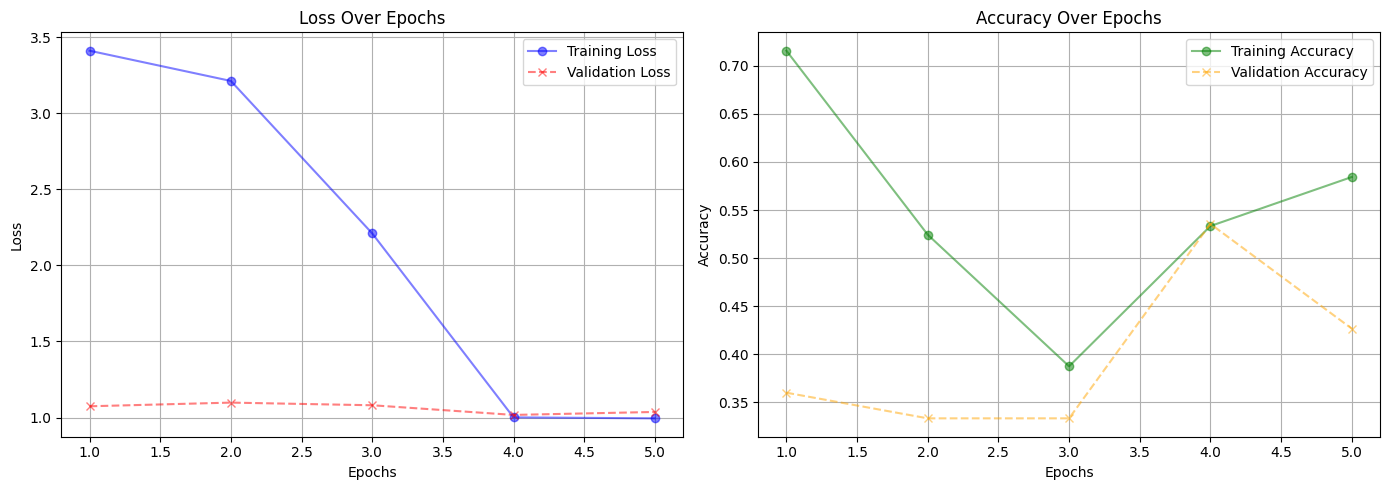

In [ ]:
plot_loss_accuracy(history_A)

Epoch 1/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.7141 - loss: 3.1476 - val_accuracy: 0.3333 - val_loss: 1.0199
Epoch 2/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.6000 - loss: 2.5278 - val_accuracy: 0.5667 - val_loss: 1.0495
Epoch 3/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.5486 - loss: 1.0329 - val_accuracy: 0.3378 - val_loss: 1.1100
Epoch 4/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.5706 - loss: 0.9698 - val_accuracy: 0.6267 - val_loss: 0.9374
Epoch 5/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.6024 - loss: 1.1933 - val_accuracy: 0.4933 - val_loss: 1.1327


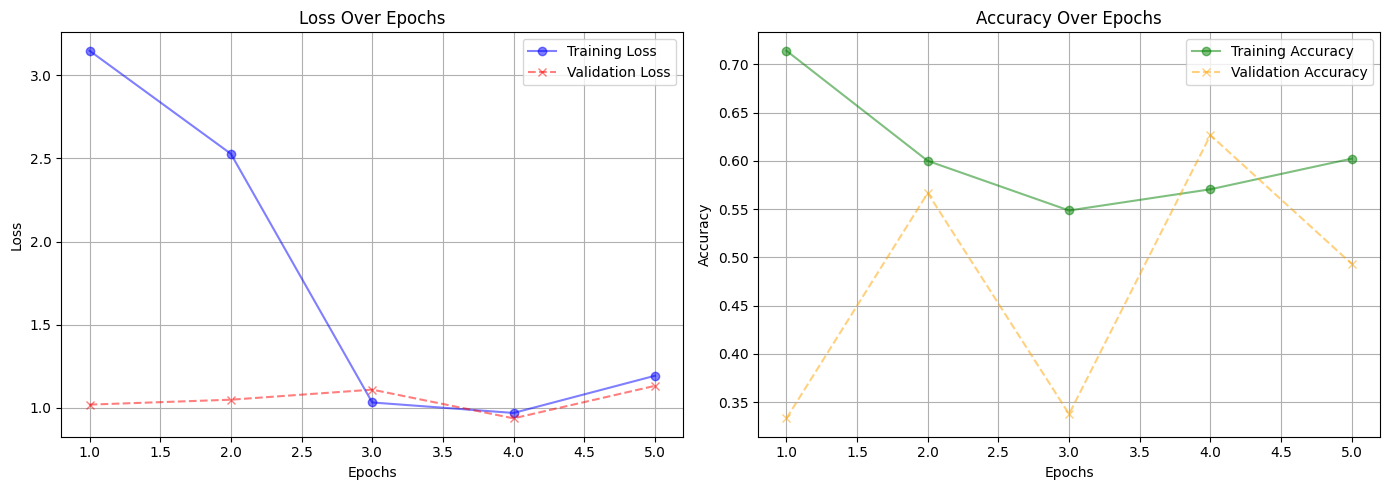

In [ ]:
# BEGIN YOUR CODE HERE
# DEFINE MODEL  B, train, plot results
tf.keras.utils.set_random_seed(42)

model_B = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(img_height, img_width, 3)),
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(num_classes)
])

# compile model
model_B.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# train model
history_B = model_B.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds
)

# plot loss/accuracy
plot_loss_accuracy(history_B)
# END YOUR CODE HERE

Epoch 1/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 66ms/step - accuracy: 0.7031 - loss: 2.3389 - val_accuracy: 0.3333 - val_loss: 1.0570
Epoch 2/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.6098 - loss: 4.1614 - val_accuracy: 0.3533 - val_loss: 1.0885
Epoch 3/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.2455 - loss: 1.4405 - val_accuracy: 0.3333 - val_loss: 1.0860
Epoch 4/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.2667 - loss: 1.0832 - val_accuracy: 0.4289 - val_loss: 1.0304
Epoch 5/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.2729 - loss: 0.9972 - val_accuracy: 0.4000 - val_loss: 1.2652


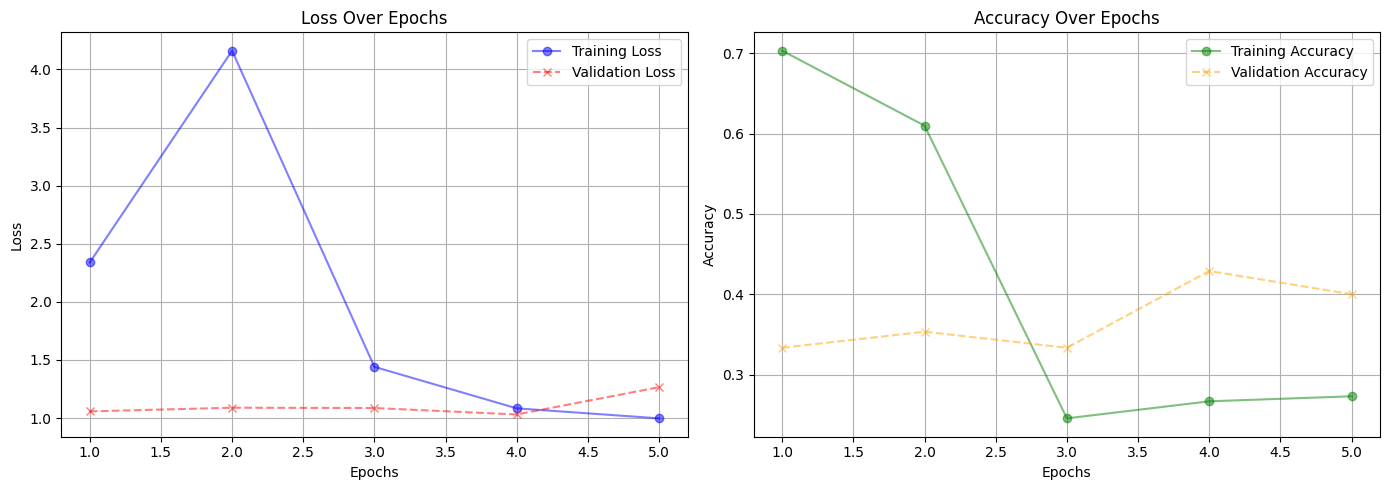

In [ ]:
# BEGIN YOUR CODE HERE
# DEFINE MODEL  C, train, plot results
tf.keras.utils.set_random_seed(42)

model_C = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(img_height, img_width, 3)),
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(num_classes)
])

# compile model
model_C.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# train model
history_C = model_C.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds,
    class_weight=class_weights
)

# plot loss/accuracy
plot_loss_accuracy(history_C)
# END YOUR CODE HERE

Epoch 1/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 76ms/step - accuracy: 0.7035 - loss: 2.3551 - val_accuracy: 0.3311 - val_loss: 1.0537
Epoch 2/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6114 - loss: 4.3746 - val_accuracy: 0.3333 - val_loss: 1.1837
Epoch 3/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.4173 - loss: 2.4207 - val_accuracy: 0.3333 - val_loss: 1.0934
Epoch 4/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.1812 - loss: 1.0867 - val_accuracy: 0.4844 - val_loss: 1.0303
Epoch 5/5
80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.3659 - loss: 2.0226 - val_accuracy: 0.3333 - val_loss: 1.3027


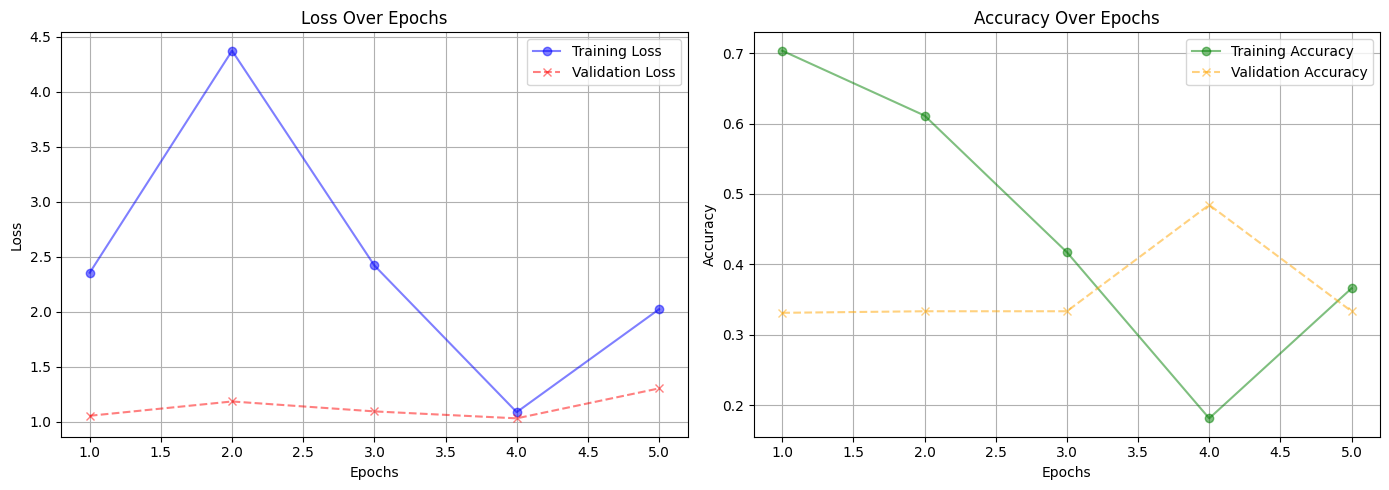

In [ ]:
# BEGIN YOUR CODE HERE
# DEFINE MODEL  D, train, plot results

tf.keras.utils.set_random_seed(42)

model_D = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(img_height, img_width, 3)),
    tf.keras.layers.Rescaling(1./255),

    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(num_classes)
])

# compile model
model_D.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# train model
history_D = model_D.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds,
    class_weight=class_weights
)

# plot loss/accuracy
plot_loss_accuracy(history_D)
# END YOUR CODE HERE

In [ ]:

from sklearn.metrics import f1_score
import pandas as pd

# Correct validation labels
true_labels = np.concatenate(
    [labels.numpy() for images, labels in val_ds]
)

results = []

for name, model, history in [
    ("A", model_A, history_A),
    ("B", model_B, history_B),
    ("C", model_C, history_C),
    ("D", model_D, history_D)
]:
    loss, accuracy = model.evaluate(val_ds, verbose=0)

    predictions = model.predict(val_ds, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)

    macro_f1 = f1_score(
        true_labels, predicted_labels, average="macro"
    )

    results.append({
        "Model": name,
        "Val Loss": loss,
        "Val Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Epochs": len(history.history["loss"]),
        "Parameters": model.count_params()
    })

results_table = pd.DataFrame(results)
print(results_table.round(4))


  Model  Val Loss  Val Accuracy  Macro F1  Epochs  Parameters
0     A    1.0367        0.4267    0.3348       5     3692003
1     B    1.1327        0.4933    0.3878       5     3692003
2     C    1.2652        0.4000    0.2878       5     3692003
3     D    1.3027        0.3333    0.1667       5     3692003


## Task 4 | Select once, then evaluate on the held-out test set

**Selection rule:** highest **validation macro-F1**; tie-breaker is lower validation loss. Do not inspect or use test results to change this choice.

In [ ]:

# Select the best model using validation results

best_id = "B"

models = {
    "A": model_A,
    "B": model_B,
    "C": model_C,
    "D": model_D
}

best_model = models[best_id]

print("highest model:", best_id)


highest model: B


In [ ]:
# Let's load the testing dataset
test_ds = tf.keras.utils.image_dataset_from_directory(
  test_data_dir,
  image_size=(img_height, img_width),
  batch_size=batch_size,
  shuffle=False   # 🔑 Ensure labels line up with predictions)
)

Found 900 files belonging to 3 classes.


Test loss: 1.216381549835205
Test accuracy: 0.41999998688697815
Classification report:
              precision    recall  f1-score   support

      glioma       0.00      0.00      0.00       300
     notumor       0.46      0.55      0.50       300
   pituitary       0.40      0.71      0.51       300

    accuracy                           0.42       900
   macro avg       0.28      0.42      0.34       900
weighted avg       0.28      0.42      0.34       900



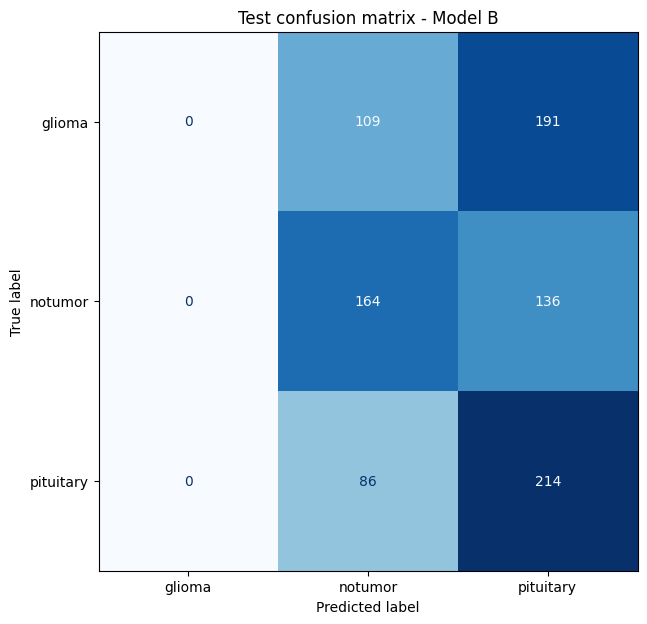

In [ ]:
# BEGIN YOUR CODE HERE
# What is the loss and accuracy on the Testing dataset?
# Tip: instead of (x_test, y_test) we used in the lab last week, you can use
# directly test_ds which contains both data and labels
# https://www.tensorflow.org/api_docs/python/tf/keras/Model#evaluate
# When you print the output of the evaluate function is run, it will return both
# the loss and accuracy, maybe in a  format like [loss_value, accuracy_value]
# print("Model accuracy on the test set is:", model.evaluate(test_ds))

best_model = model_B

# Evaluate the selected model
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=0)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

# Get true labels and predictions
y_test = np.concatenate([y for x, y in test_ds], axis=0)

predictions = best_model.predict(test_ds, verbose=0)
predicted_labels = np.argmax(predictions, axis=1)

# Print classification report
class_names = train_ds.class_names

print("Classification report:")
print(classification_report(
    y_test,
    predicted_labels,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

# Compute and plot confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, predicted_labels, labels=[0, 1, 2])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(cmap="Blues", values_format="d", colorbar=False)

plt.title("Test confusion matrix - Model " + best_id)
plt.show()
# END YOUR CODE HERE

In [ ]:
# Try to improve the model as much as you can